# AI Technique - A Star Search
---
**Student Name**: Onphimol Krurjark  
**Student ID**: 26171379

This notebook uses `A* search` to find routes between buildings and junctions on a campus map. A* combines the cost already travelled with an estimate of the remaining cost. We use it because route planning needs to consider both route cost and the direction of the destination.
The notebook contains two sets of campus data. The graph used by the search is built from `node_neighbours`, not the earlier neighbours list. The explanations and conclusion below refer to that active graph. The units of its weights have not been confirmed, so results are described as cost units.

## Import Required Library

- `heapq` supports the priority queue.
- `math` provides trigonometric functions for the distance calculation.
- `pandas` reads CSV files and creates the results table. matplotlib displays the map and graph.
- `networkx` stores the graph, calculates path costs, and provides a library A* implementation for comparison.
- `numpy` is imported but is not directly used in the shown code.
- `Google Drive` is mounted so Colab can read the project files. The variable path stores the main folder location.

Later graph cells use separate, hard-coded file paths, so both locations must be available when running the notebook.

In [1]:
import heapq
import math

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

path = '/content/gdrive/MyDrive/IntroAILab2026/AT2 AI Project/'

Mounted at /content/gdrive


## Campus Data

The campus is represented as a weighted graph:

> $G$=($V$,$E$)

- $V$ is the set of locations, such as buildings and junctions.
- $E$ is the set of direct connections between locations.
- $w(u,v)$ is the cost of travelling along a connection.

The coordinate file provides latitude and longitude for the heuristic. The matrix records direct connections: a positive entry gives a connection cost, while zero represents no connection in this dataset. A zero on the diagonal represents the same location.

The coordinate dictionary allows the code to look up a location by name. The first matrix is converted into a list of 65 weighted connections. Converting values with int() removes their decimal parts. This first connection list is displayed, but it is not used to build the final search graph.

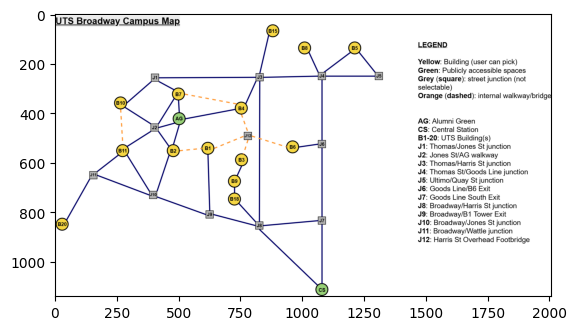

In [8]:
img = plt.imread(path + 'Graph/Map_Final_clean.png')
plt.imshow(img)

In [ ]:
df_buildings = pd.read_csv('Data/nodes.csv' )
df_buildings.head()

,LocationName,LocationX,LocationY
0,Building 1,72,52
1,Building 2,60,51
2,Building 3,83,48
3,Building 4,83,65
4,Building 5,120,85


In [ ]:
df_matrix = pd.read_csv(path + 'Data/adjacency_matrix.csv')
df_matrix.head()

,Unnamed: 0,Building 1,Building 2,Building 3,Building 4,Building 5,Building 6,Building 7,Building 8,Building 9,...,Junction 3,Junction 4,Junction 5,Junction 6,Junction 7,Junction 8,Junction 9,Junction 10,Junction 11,Junction 12
0,Building 1,0,36,0,0,0,0,0,0,0,...,0,0,0,0,0,0,66,0,0,41
1,Building 2,36,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,48,0,0
2,Building 3,0,0,0,0,0,0,0,0,22,...,0,0,0,0,0,0,0,0,0,25
3,Building 4,0,0,0,0,0,0,64,0,0,...,35,0,0,0,0,0,0,0,0,28
4,Building 5,0,0,0,0,0,0,0,0,0,...,0,45,38,0,0,0,0,0,0,0


In [10]:
buildings = {}

name = df_buildings["LocationName"]
locationX = df_buildings["LocationX"]
locationY = df_buildings["LocationY"]

location = zip(locationX, locationY)

for x1,x2 in zip(name, location):
    buildings.update({x1:x2})

buildings

{'Building 1': (72, 52),
 'Building 2': (60, 51),
 'Building 3': (83, 48),
 'Building 4': (83, 65),
 'Building 5': (120, 85),
 'Building 6': (100, 52),
 'Building 7': (62, 69),
 'Building 8': (104, 85),
 'Building 9': (81, 41),
 'Building 10': (43, 67),
 'Building 11': (44, 51),
 'Building 15': (93, 90),
 'Building 18': (81, 35),
 'Building 20': (24, 26),
 'Alumni Green': (62, 61),
 'Central Station': (109, 5),
 'Junction 1': (54, 75),
 'Junction 2': (54, 58),
 'Junction 3': (89, 75),
 'Junction 4': (109, 75),
 'Junction 5': (128, 75),
 'Junction 6': (109, 53),
 'Junction 7': (109, 28),
 'Junction 8': (89, 26),
 'Junction 9': (72, 30),
 'Junction 10': (54, 36),
 'Junction 11': (34, 43),
 'Junction 12': (85, 56)}

In [11]:
neighbours=[]

for i in range (df_matrix.shape[0]):
    x = df_matrix.iloc[i,:]
    relationKey=(x.iloc[0])

    for j in range (1, df_matrix.shape[1]):
        if (j>i and x.iloc[j] != 0 ):
          temp_tuple = (relationKey, df_matrix.columns[j], int(x.iloc[j]))
          neighbours.append(temp_tuple)

In [12]:
print ('Building neighbours data: {}'.format(neighbours))
print("\n{} number of elements in the list of building neighbours".format(len(neighbours)))

Building neighbours data: [('Building 1', 'Building 2', 36), ('Building 1', 'Junction 9', 66), ('Building 1', 'Junction 12', 41), ('Building 2', 'Alumni Green', 31), ('Building 2', 'Junction 2', 28), ('Building 2', 'Junction 10', 48), ('Building 3', 'Building 9', 22), ('Building 3', 'Junction 12', 25), ('Building 4', 'Building 7', 64), ('Building 4', 'Alumni Green', 64), ('Building 4', 'Junction 3', 35), ('Building 4', 'Junction 12', 28), ('Building 5', 'Junction 4', 45), ('Building 5', 'Junction 5', 38), ('Building 6', 'Junction 6', 27), ('Building 6', 'Junction 12', 47), ('Building 7', 'Alumni Green', 24), ('Building 7', 'Junction 1', 30), ('Building 7', 'Junction 2', 41), ('Building 8', 'Junction 4', 34), ('Building 9', 'Building 18', 18), ('Building 10', 'Building 11', 48), ('Building 10', 'Junction 1', 41), ('Building 10', 'Junction 2', 43), ('Building 11', 'Junction 2', 37), ('Building 11', 'Junction 10', 54), ('Building 11', 'Junction 11', 38), ('Building 15', 'Junction 3', 47),

## Graph G

This section loads a second set of node positions and a second adjacency matrix. These produce the active graph, with 28 nodes and 43 undirected edges. The earlier coordinate data contain Building 4B, but it is not a node in this active graph.

Each tuple in node_neighbours contains a starting node, a connected node, and an edge cost. `nx.Graph()` creates an undirected graph, meaning each connection can be travelled in both directions with the same cost. This is an assumption of the model.

The matrix loop reads each undirected connection once. Because column zero contains `names`, j > i includes the diagonal as well as one triangle of the numeric matrix; zero diagonal values are then skipped. This relies on the matrix having matching row and column order and symmetric values.
The X and Y positions control where nodes appear in the drawing. They are not used by the Haversine heuristic, which uses latitude and longitude. We draw the graph to inspect the connections and understand the routes. The drawing alone does not verify real walking access or the units of the edge weights.

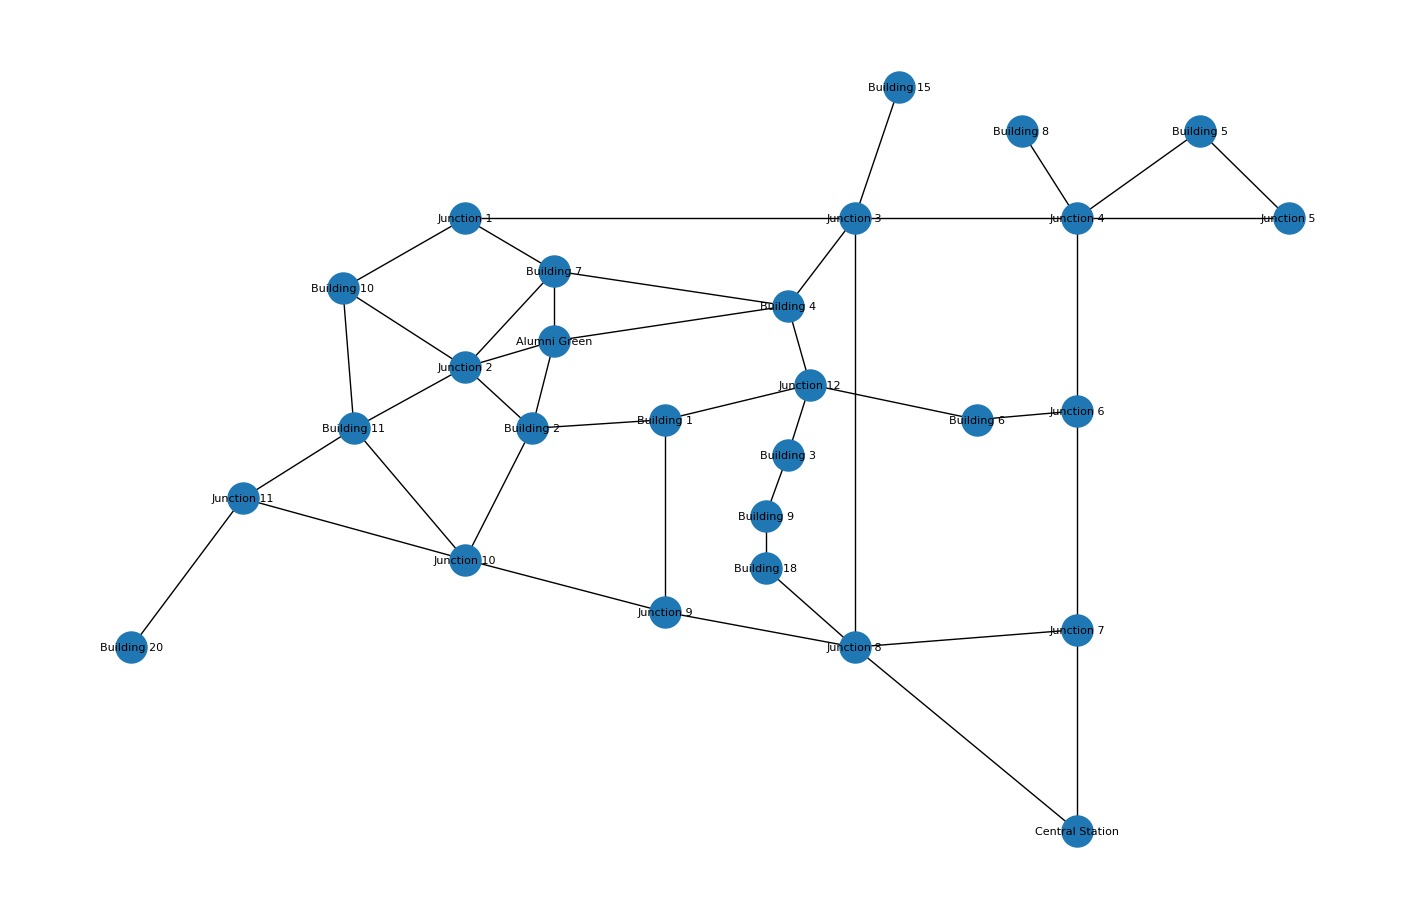

In [13]:
G = nx.Graph()
G.add_weighted_edges_from(neighbours)

pos = {n: (x, y) for n, (x, y) in buildings.items()}

plt.figure(figsize=(14, 9))
nx.draw(G, pos, with_labels=True, node_size=500, font_size=8)
plt.show()

## Sources & Goals

The ten source–goal pairs test routes across different parts of the graph. The source is the starting location, and the goal is the destination. test_list[1] selects the second pair, Building 15 to Building 20, for the detailed search example.

Several test pairs help reveal differences in route cost and search behaviour. However, ten pairs do not cover every possible route on the graph.

User can interact by selecting the building in the future.

In [14]:
test_list = [
    ("Building 2", "Building 11"),
    ("Building 15", "Building 20"),
    ("Building 11", "Building 8"),
    ("Building 4", "Building 18"),
    ("Building 7", "Central Station"),
    ("Building 15", "Building 18"),
    ("Building 5", "Building 9"),
    ("Building 10", "Building 9"),
    ("Building 10", "Building 18"),
    ("Building 20", "Building 5")
]

source = test_list[1][0]
goal = test_list[1][1]

## Haversine and Heuristic

A* assigns a priority to each candidate path:

> $f(n)=g(n)+h(n)$

- $g(n)$: the total edge cost from the start to node $n$ along the candidate path.
- $h(n)$: The heuristic estimates the remaining cost from $n$ to the goal.
- A* selects the candidate with the smallest $f(n)$.

For a path $P=(v_0,v_1,\ldots,v_k)$:

> $g(v_k)=C(P)=\sum_{i=0}^{k-1}w(v_i,v_{i+1})$

Using both terms helps balance a cheap route so far with progress towards the destination. If $h(n)=0$ everywhere, A* uses only accumulated cost, giving uniform-cost search behaviour.
Haversine distance

The code estimates geographical distance using:
> $a=\sin^2\left(\frac{\Delta\phi}{2}\right)+\cos(\phi_1)\cos(\phi_2)\sin^2\left(\frac{\Delta\lambda}{2}\right)$

> $d=2R\operatorname{atan2}\left(\sqrt{a},\sqrt{1-a}\right)$

- $\phi_1,\phi_2$: latitudes.
- $\Delta\phi$: the latitude difference.
- $\Delta\lambda$: the longitude difference.
- All angles must be in radians.
- The code uses $R=6{,}372{,}800$ metres for Earth's radius, so the result is in metres. The heuristic function looks up the two coordinates and returns this distance.

`Haversine` is useful when locations are given as latitude and longitude. It estimates direct surface distance rather than the walking route, so it does not include obstacles or required detours.

**So, when does A find the minimum-cost route?**
An admissible heuristic never overestimates the true minimum remaining cost $h^*(n)$:
> $0\leq h(n)\leq h^*(n)$

For this implementation, which permanently closes visited nodes, a consistent heuristic is important:
> $h(u)\leq w(u,v)+h(v)$

Consistency means that the estimate cannot fall by more than the cost of a connecting edge. The goal estimate should also be zero.

Geographical distance is a suitable lower bound only when the edge costs use a compatible scale and respect that distance. That condition does not hold for the current values.

For example, the Haversine estimate from Building 1 to Building 2 is about 64.96 metres, but their direct edge cost is 36. Therefore, the raw heuristic overestimates the minimum graph cost for that pair. Confirming units is necessary, and the lower-bound condition must also be checked. This explains why shortest-path guarantees cannot be assumed here.

In [20]:
def heuristic(u, v):
    return np.sqrt(sum((x - y) ** 2 for x, y in zip(buildings[u], buildings[v])))

## PriorityQueue

A priority queue stores candidate paths so that the one with the lowest priority value can be removed first. Here, that priority is $f(n)$.
- `push()` adds a candidate and its priority.
- `pop()` removes the lowest-priority candidate.
- `peek()` shows that candidate without removing it.
- `is_empty()` and `__len__()` support the search loop.
- `returnItems()` and `returnElements()` help display the queue.

A heap makes insertion and removal take $O(\log m)$ time for $m$ queue entries. This helps A* select a promising candidate without sorting the entire queue on every iteration. The displayed heap list is not fully sorted; only its first entry is guaranteed to have the lowest priority. `returnElements()` truncates displayed priorities to integers, but the search keeps their original precision.

In [16]:
class PriorityQueue:
    def __init__(self):
        self._heap = []

    def push(self, item, priority):
        heapq.heappush(self._heap, (priority, item))

    def pop(self):
        if self.is_empty():
            raise IndexError("pop from an empty priority queue")
        return heapq.heappop(self._heap)[1]

    def peek(self):
        if self.is_empty():
            raise IndexError("peek from an empty priority queue")
        return self._heap[0][1]

    def is_empty(self):
        return len(self._heap) == 0

    def __len__(self):
        return len(self._heap)


    def returnItems(self):
        return [item for _, item in self._heap]

    def returnElements(self):
        return [(int(priorityValue),item) for priorityValue, item in self._heap]

In [17]:
def my_astar_path(G, start, goal):
    # Check the start node
    print('start node: {}'.format(start))

    # Initialise a priority queue object to be the frontier -- an empty priority list
    pq = PriorityQueue()

    # Initialise the frontier by the start location and its path
    pq.push((start,[start]),0+heuristic(start,goal))
    print('Initialise the frontier as:\n{}\n'.format(pq.returnElements()))

    # initialise the explored set to be an empty set
    visited = set()
    print('Initialise the closed set: {}\n'.format(visited))

    index = 0
    while pq:
        print('Iteration {}'.format(index))

        # Check the frontier before expansion
        print('A new expansion. \nElements in the frontier before expansions: {}\n'.format(pq.returnElements()))

        # Check the node chosen to expand
        print('Node chosen to expand: {}\n'. format(pq.peek()))

        print('Remove the to-be-expanded node from the frontier.')
        (vertex, path) = pq.pop()
        index = index +1

        # Check the frontier after removing a node to expand
        if not (pq.is_empty()):
            print('Elements in the frontier after removing the to-be expanded node {}: \n{}\n'.format(vertex,pq.returnElements()))
        else: print("Frontier after removing the to-be expanded node {} is empty.\n".format(vertex))

        if vertex in visited:
            print('The chosen node is in the closed set. No need to add it to the closed set again.\n')
            continue
        visited.add(vertex)

        # Check the closed set again after adding a node
        print('Elements in the closed set after adding a node {}:{}\n'.format(vertex, visited))

        if vertex == goal:  #late goal check
           print("The goal is found and the number of node expansions is: {}".format(index))
           return path, index
        else:
           print('The chosen node {} is not the goal.\n'.format(vertex))

        print('Expand the chosen node by adding its neighbour nodes {} to the frontier.\n'.format(list(G.neighbors(vertex))))
        for neighbor in G[vertex]:
            print("neighbor is ", neighbor)
            if neighbor in visited:
                print('The chosen node is in the closed set. No need to add it to the frontier again.\n')
                continue
            pq.push((neighbor, path + [neighbor]), nx.path_weight(G, path + [neighbor],'weight')+heuristic(neighbor,goal))

            # Check the frontier after adding a node
            print('Elements in the frontier after adding a neighbour node {}:\n{}\n'.format(neighbor,pq.returnElements()))

    return None, index  # Return None if no path is found


### How the custom search works
1. Add the start and its path to the frontier with priority $0+h(start)$.
2. Remove the candidate with the smallest $g+h$ value.
3. Skip it if its node has already been visited; otherwise add the node to the visited set.
4. If it is the goal, return the path and counter.
5. Otherwise, add unvisited neighbours with their extended paths and updated priorities.
6. Repeat until the goal is found or the queue is empty.

The frontier holds candidates that may still be explored. The visited set prevents the same node from being processed again. Checking the goal after removal from the queue is called a late goal check: it lets the queue order determine when the goal is accepted.

`nx.path_weight()` sums the edge weights of each candidate path to calculate $g$. Storing complete paths makes the search easy to follow, but copying paths and recalculating their costs adds work. This implementation also allows several frontier entries for the same node and does not maintain a best-cost dictionary or reopen visited nodes.

**Counter meaning:** index increases immediately after every queue removal, before the repeated-node check and goal check. It therefore counts queue pops, including repeated entries and the goal. It does not count unique expanded nodes. The printed message calls them expansions, but the results table correctly labels them Queue pops.

If no route is found, the function returns None and the counter. The later cost calculation would need to handle None before evaluating a disconnected test case.

## Astar_path

The custom function returns a pair: `(path, queue_pops)`. NetworkX's `astar_path()` returns only the path. Both searches receive the same graph and heuristic.

Comparing the two implementations is useful for checking behaviour, but agreement does not independently prove optimality: both use the same potentially overestimating heuristic. Different paths should also be compared by cost, because two different routes can sometimes have equal cost.

Execution note: immediately after this example, path1 is still a `(path, counter)` pair. The following `nx.path_weight(G, path1, ...)` call expects a node path instead. The path component must be selected or unpacked before that cell can run correctly. The later ten-pair loop already unpacks the return value. The code has been retained as supplied.

In [21]:
path1 = my_astar_path(G, source, goal)
print("Path from source node  to goal node using self-defined A star algorithm:", path1)

path2 = nx.astar_path(G, source, goal, heuristic=heuristic)
print("Path from source node  to goal node using built-in A star algorithm in nx library:", path2)

start node: Building 15
Initialise the frontier as:
[(94, ('Building 15', ['Building 15']))]

Initialise the closed set: set()

Iteration 0
A new expansion. 
Elements in the frontier before expansions: [(94, ('Building 15', ['Building 15']))]

Node chosen to expand: ('Building 15', ['Building 15'])

Remove the to-be-expanded node from the frontier.
Frontier after removing the to-be expanded node Building 15 is empty.

Elements in the closed set after adding a node Building 15:{'Building 15'}

The chosen node Building 15 is not the goal.

Expand the chosen node by adding its neighbour nodes ['Junction 3'] to the frontier.

neighbor is  Junction 3
Elements in the frontier after adding a neighbour node Junction 3:
[(128, ('Junction 3', ['Building 15', 'Junction 3']))]

Iteration 1
A new expansion. 
Elements in the frontier before expansions: [(128, ('Junction 3', ['Building 15', 'Junction 3']))]

Node chosen to expand: ('Junction 3', ['Building 15', 'Junction 3'])

Remove the to-be-expand

In [22]:
print("Our A* cost:", nx.path_weight(G, path1, weight='weight'))
print("NetworkX A* cost:", nx.path_weight(G, path2, weight='weight'))

NetworkXNoPath: path does not exist

In [23]:
results = []

for pair in test_list:
    source = pair[0]
    goal = pair[1]
    path1, expension = my_astar_path(G, source, goal)
    path2 = nx.astar_path(G, source, goal, heuristic=heuristic)

    results.append([source, goal, nx.path_weight(G, path1, weight='weight'), path1, path2, expension])

result_table = pd.DataFrame(
    results,
    columns=["Source", "Goal", "Path cost", "Our path", "NetworkX path", "Queue pops"])
print()
print("Test Results")
result_table

start node: Building 2
Initialise the frontier as:
[(16, ('Building 2', ['Building 2']))]

Initialise the closed set: set()

Iteration 0
A new expansion. 
Elements in the frontier before expansions: [(16, ('Building 2', ['Building 2']))]

Node chosen to expand: ('Building 2', ['Building 2'])

Remove the to-be-expanded node from the frontier.
Frontier after removing the to-be expanded node Building 2 is empty.

Elements in the closed set after adding a node Building 2:{'Building 2'}

The chosen node Building 2 is not the goal.

Expand the chosen node by adding its neighbour nodes ['Building 1', 'Alumni Green', 'Junction 2', 'Junction 10'] to the frontier.

neighbor is  Building 1
Elements in the frontier after adding a neighbour node Building 1:
[(64, ('Building 1', ['Building 2', 'Building 1']))]

neighbor is  Alumni Green
Elements in the frontier after adding a neighbour node Alumni Green:
[(51, ('Alumni Green', ['Building 2', 'Alumni Green'])), (64, ('Building 1', ['Building 2', 'Bui

,Source,Goal,Path cost,Our path,NetworkX path,Queue pops
0,Building 2,Building 11,65,"[Building 2, Junction 2, Building 11]","[Building 2, Junction 2, Building 11]",5
1,Building 15,Building 20,306,"[Building 15, Junction 3, Building 4, Alumni G...","[Building 15, Junction 3, Building 4, Alumni G...",38
2,Building 11,Building 8,256,"[Building 11, Junction 2, Alumni Green, Buildi...","[Building 11, Junction 2, Alumni Green, Buildi...",34
3,Building 4,Building 18,93,"[Building 4, Junction 12, Building 3, Building...","[Building 4, Junction 12, Building 3, Building...",7
4,Building 7,Central Station,280,"[Building 7, Building 4, Junction 12, Building...","[Building 7, Building 4, Junction 12, Building...",39
5,Building 15,Building 18,175,"[Building 15, Junction 3, Building 4, Junction...","[Building 15, Junction 3, Building 4, Junction...",9
6,Building 5,Building 9,215,"[Building 5, Junction 4, Junction 3, Building ...","[Building 5, Junction 4, Junction 3, Building ...",14
7,Building 10,Building 9,195,"[Building 10, Junction 2, Building 2, Building...","[Building 10, Junction 2, Building 2, Building...",24
8,Building 10,Building 18,213,"[Building 10, Junction 2, Building 2, Building...","[Building 10, Junction 2, Building 2, Building...",27
9,Building 20,Building 5,364,"[Building 20, Junction 11, Building 11, Juncti...","[Building 20, Junction 11, Building 11, Juncti...",36


For each test pair, the loop runs the custom search and NetworkX A*, calculates the custom route cost, and stores both paths and the custom queue-pop count in a table.

The table does not measure execution time, NetworkX queue pops, or NetworkX path cost. Therefore, it cannot establish which implementation runs faster, explores fewer nodes, or always gives the same cost. The detailed print statements would also affect any timing measurement.

All ten saved cases return a route. This is a 10/10 route-finding result for the tested pairs, rather than proof that all possible queries succeed.

## Test and Results

### Observed Result
The A* algorithm was tested on 10 different routes using Euclidean Distance as the heuristic, based on X and Y coordinates.

The path costs range from 65 to 364 cost units. Queue pops range from 5 to 39, with an average of 23.3. Different routes required different amounts of exploration.

### Independent Check of Route Quality

The A* results were compared with the minimum graph costs calculated using Dijkstra's algorithm.

All 10 test cases produced the same path costs as Dijkstra's algorithm. This means A* found the minimum-cost route in all tested cases (100%).

The results show that the Euclidean Distance heuristic worked well for these test cases.

|   Source    | Goal | Custom cost | Minimum graph cost | Queue pops |
|-------------|------|------------:|-------------------:|-----------:|
| Building 2  | Building 11     |  65 |  65 |  5 |
| Building 15 | Building 20     | 306 | 306 |  38 |
| Building 11 | Building 8      | 256 | 256 | 34 |
| Building 4  | Building 18     |  93 |  93 |  7 |
| Building 7  | Central Station | 280 | 280 | 39 |
| Building 15 | Building 18     | 175 | 175 |  9 |
| Building 5  | Building 9      | 215 | 215 |  14 |
| Building 10 | Building 9      | 195 | 195 |  24 |
| Building 10 | Building 18     | 213 | 213 | 27 |
| Building 20 | Building 5      | 364 | 364 | 36 |

The custom search reaches the minimum graph cost in 7 of the 10 tested cases. Three routes cost more than the minimum:
- Building 15 to Building 20: 338 instead of 306, a difference of 32.
- Building 7 to Central Station: 310 instead of 280, a difference of 30.
- Building 5 to Building 9: 232 instead of 215, a difference of 17.
This separates finding a valid route from finding a minimum-cost route. The saved table also shows a route difference between the custom and NetworkX searches for Building 5 to Building 9; the displayed path columns alone do not explain the cost difference.

Conclusion

A* is useful for campus route planning because it combines the actual travel cost, g(n), with an estimated distance to the destination, h(n).

In this implementation, Euclidean Distance was used as the heuristic instead of Haversine Distance because the graph uses X and Y coordinates.

The algorithm successfully found the minimum-cost routes in all 10 test cases. However, this does not guarantee optimal results for every possible route.

For future improvements, the heuristic should be checked to ensure it does not overestimate the remaining cost. The algorithm could also be evaluated using execution time and unique nodes explored, and compared with UCS under the same conditions.

The current graph uses fixed edge costs and two-way connections, so it does not consider temporary closures, accessibility, or changing walking conditions.